# Managed Money positioning across the oil complex

How do weekly changes in Managed Money positions move together across the six energy futures we track (WTI, Brent, Gasoil, Heating oil, RBOB gasoline, Natural gas), how has that changed since 2011, and what happened during the 2026 Strait of Hormuz crisis, when funds seemed to trade Brent rather than WTI? We read the results against the OIES comment *Shifting Oil Market Positioning During the Strait of Hormuz Crisis* (Sun, Bouchouev and Fattouh, October 2026).

- **Oil positions move together, but much less than prices.** Weekly changes in Managed Money correlate 0.32–0.64 across the oil pairs (returns: 0.75–0.96) and form three groups: the two crudes, the three products, and natural gas. Most of that co-movement is trend following: the discretionary part correlates 0.41 at most.
- **Co-movement has been falling since 2020.** The average oil-pair correlation was 0.47–0.63 each year to 2019 (except 2015) and 0.31–0.41 in 2020–2025, while price correlations stayed at 0.79–0.95.
- **The 2026 war split the oil block.** The 26-week WTI–Brent correlation of position changes fell from 0.55 to 0.01, and WTI–Gasoil and Gasoil–Heating oil fell to their lowest since 2011, while Brent and WTI returns correlated 0.97. WTI shared Brent's cluster in 9% of 2026 windows, against about 60% before.
- **The break is in trend following, outside Brent.** The network's trend signals stayed as correlated across the oil markets as usual (0.83), but positions stopped following them in WTI, RBOB and Gasoil, while Brent's still tracked its signal one for one (slope 1.23): the trend-following part of the average correlation fell from 0.45 to 0.02. The earlier breaks (2015, 2020, 2021) also came from positions rather than prices, but none split the crude and the distillate pairs at once.
- **Funds traded the crisis through Brent.** Brent's net position exceeded WTI's by 309 million barrels at the end of March (12 on average in 2011–2025). Funds then cut Brent by 278k contracts during the ceasefire and bought 129k back after it collapsed, while WTI moved by 20k at most per phase and its weekly changes halved.
- **This matches the OIES comment.** After the first shock, positions tracked prices in Brent (0.86, 0.76) but not in WTI (−0.17, −0.54), and discretionary length rotated from Brent (−140 million barrels) to WTI and the products during the ceasefire. Two of its findings are not reproduced: Brent's price link in the first war weeks, and Gasoil's July rise.

## Setup

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy.cluster.hierarchy import dendrogram
from IPython.display import display

REPO_ROOT = Path.cwd().parent if Path.cwd().name == 'working_ideas' else Path.cwd()
PROJECT_ROOT = REPO_ROOT / 'paper_replication'
DATA = PROJECT_ROOT / 'data_required'
sys.path[:0] = [str(PROJECT_ROOT / 'src'), str(REPO_ROOT / 'working_ideas' / 'src')]

from paper_replication.config import ReplicationConfig
from paper_replication.data import load_inputs
import positioning as P  # type: ignore

OUTPUT = PROJECT_ROOT / 'outputs' / 'position_analysis'
OUTPUT.mkdir(parents=True, exist_ok=True)
NN_FILE = PROJECT_ROOT / 'outputs' / 'neural_network' / 'model_predictions_expanded.csv'
COLORS = {'WTI': '#1d2b53', 'BRENT': '#c8553d', 'GASOIL': '#277f8e', 'HEATOIL': '#7fa7d6', 'RBOB': '#b7782c',
          'NATGAS': '#96587e', 'Positions': '#1d2b53', 'Discretionary part': '#c8553d', 'Prices': '#9a9a9a',
          'Trend part': '#277f8e'}
REGIME_COLORS = ['#1d2b53', '#7fa7d6', '#b7782c', '#c8553d', '#96587e']
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
NAMES = [P.LABELS[m] for m in P.MARKETS]
OIL = P.MARKETS[:5]
OIL_PAIRS = [p for p in P.PAIRS if 'NATGAS' not in p]
WAR_START, DATA_END = pd.Timestamp('2026-02-28'), pd.Timestamp('2026-08-25')


def pair(a, b):
    # Column name of a pair in the order of P.MARKETS.
    return f'{a}-{b}' if P.MARKETS.index(a) < P.MARKETS.index(b) else f'{b}-{a}'


def pair_label(name):
    a, b = name.split('-')
    return f'{P.LABELS[a]}–{P.LABELS[b]}'


EVENT_NOTE = 'dashed lines: war begins and Hormuz closes (28 Feb), ceasefire (7 Apr), ceasefire collapses (8 Jul)'


def mark_events(ax):
    # Dashed lines at the 2026 events (EVENT_NOTE).
    for date in P.EVENTS:
        ax.axvline(pd.Timestamp(date), color='black', lw=.8, ls='--', alpha=.6)


def shade_war(ax):
    ax.axvspan(WAR_START, DATA_END, color=COLORS['BRENT'], alpha=.12, lw=0)


def heatmap(ax, corr, title, fontsize=8):
    names = [P.LABELS[m] for m in corr.index]
    ax.imshow(corr.to_numpy(), cmap='RdBu_r', vmin=-1, vmax=1)
    ax.set_xticks(range(len(names)), names, rotation=45, ha='right')
    ax.set_yticks(range(len(names)), names)
    for i in range(len(names)):
        for j in range(len(names)):
            v = corr.iat[i, j]
            ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=fontsize,
                    color='white' if abs(v) > .6 else 'black')
    ax.set_title(title, fontsize=fontsize + 2)
    ax.spines[:].set_visible(False)

## Data

- **Positions:** weekly COT Managed Money net positions, futures only, as of each Tuesday's close (`paper_replication/data_required/managed_money.csv`): CFTC for WTI, Heating oil, RBOB and Natural gas, ICE Futures Europe for Brent and Gasoil. The ICE series start in January 2011, so the six-market sample runs from 2011 to 25 August 2026. We study the weekly change in each market's net position, in contracts. Brent, WTI, Heating oil and RBOB contracts all hold 1,000 barrels and Gasoil about 745, so oil positions are close to comparable in barrels; Natural gas is not.
- **Prices:** the log return of each market's held futures contract between consecutive COT dates (Tuesday to Tuesday), on the rolling contract of `paper_replication` (`build_rolling_contract`), and Brent and WTI front-month settlements.
- **Discretionary part:** the replicated Insight 177 network predicts each week's change in Managed Money from momentum inputs only: its bias, the slow discretionary level, is held fixed between the two weeks, so the predicted change is the trend part. The weekly change minus that prediction is what the OIES comment calls the discretionary change, plus model error (the network explains about 45% of weekly changes). It comes from the network's expanded run (2015–2026), each week fitted on the previous two years only.
- **2026 events** (Wikipedia, hormuz.now, CRS; sources differ by a day): the US and Israel strike Iran and Iran closes the Strait of Hormuz on 28 February (the first COT week after is 3 March), a two-week ceasefire on 7 April, and its collapse on 8 July.

In [2]:
pos = P.load_positions(DATA / 'managed_money.csv')
prices, meta, _ = load_inputs(ReplicationConfig(data_dir=DATA))
changes = pos['net'].diff().iloc[1:]
returns = P.weekly_returns(prices, meta, pos['report_date']).loc[changes.index]
nn = P.nn_discretionary(NN_FILE)
discretionary = nn['discretionary'].loc['2015':]
trend_part = nn['trend'].loc['2015':]

common = changes.index.intersection(nn['actual'].index)
print(f"{len(changes)} weeks of changes, {changes.index[0]:%Y-%m-%d} to {changes.index[-1]:%Y-%m-%d}; "
      f"discretionary part from {discretionary.index[0]:%Y-%m-%d}")
print(f"Network file agrees with the COT changes to {(nn['actual'].loc[common] - changes.loc[common]).abs().max().max():.0f} contracts; "
      f"predicted change = mm_std_lag x (trend_cur - trend_prev) to {nn['identity_gap'].max().max():.2f} contracts")
spread = changes.groupby(changes.index.year).std().div(1e3).rename(columns=P.LABELS)
display(spread.loc[[2019, 2023, 2024, 2025, 2026]].round(1).rename_axis('Std of weekly change (k contracts)'))

816 weeks of changes, 2011-01-11 to 2026-08-25; discretionary part from 2015-01-06
Network file agrees with the COT changes to 0 contracts; predicted change = mm_std_lag x (trend_cur - trend_prev) to 0.03 contracts


market,WTI,Brent,Gasoil,Heating oil,RBOB,Nat gas
Std of weekly change (k contracts),,,,,,
2019,31.9,25.0,13.7,5.4,8.7,29.5
2023,29.9,35.5,11.8,4.7,7.7,21.3
2024,30.3,40.6,17.9,7.6,6.9,27.6
2025,25.3,44.9,16.2,7.9,10.0,20.2
2026,13.1,33.9,8.6,4.7,5.0,23.2


**Reading.** 2026 stands out in the size of weekly changes. Brent's stayed large (standard deviation 33.9k contracts, against 35.5k–44.9k in 2023–25), while WTI's halved to 13.1k (25.3k–30.3k in 2023–25), and Gasoil's and RBOB's also shrank (8.6k and 5.0k, from 11.8k–17.9k and 6.9k–10.0k). Natural gas was unaffected (23.2k).

## The full-sample correlation matrix

Three clusters of positions: {1: ['WTI', 'Brent'], 2: ['Gasoil', 'Heating oil', 'RBOB'], 3: ['Nat gas']}


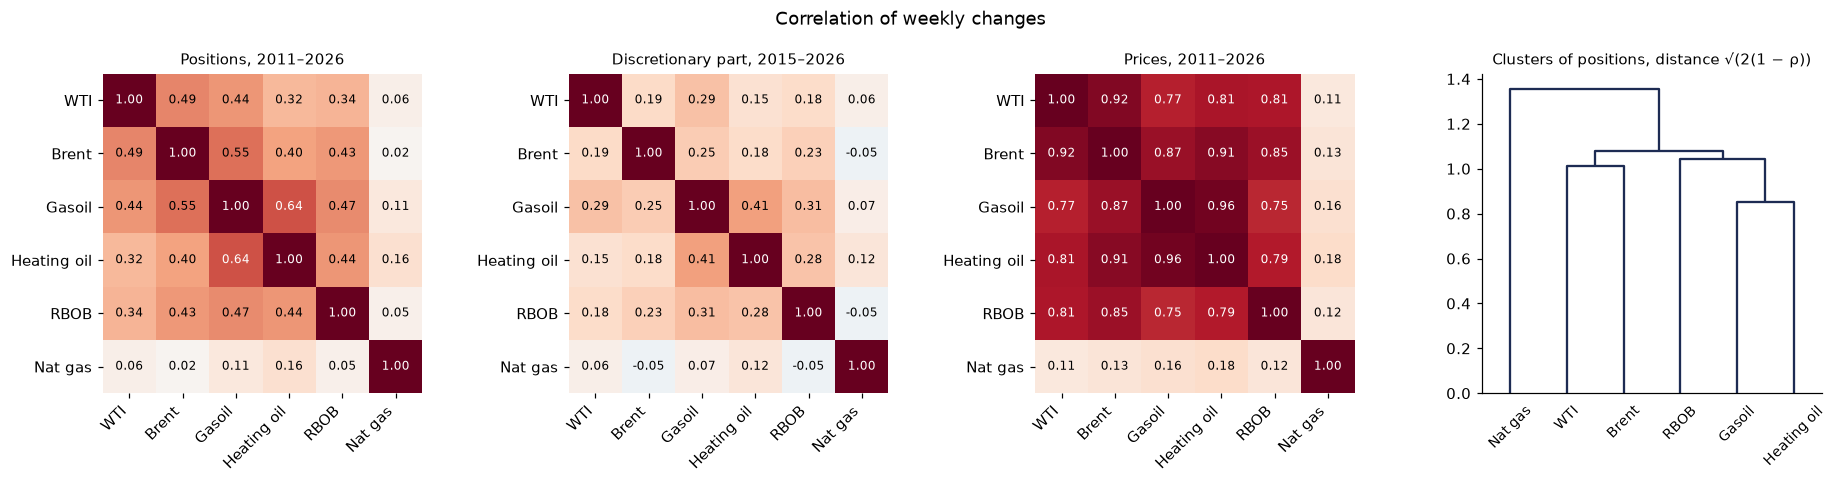

In [3]:
full = {'Positions, 2011–2026': changes.corr(),
        'Discretionary part, 2015–2026': discretionary.corr(),
        'Prices, 2011–2026': returns.corr()}
fig, axes = plt.subplots(1, 4, figsize=(17, 4.4), gridspec_kw={'width_ratios': [1, 1, 1, .95]})
for ax, (title, corr) in zip(axes, full.items()):
    heatmap(ax, corr, title)
labels, z = P.market_clusters(full['Positions, 2011–2026'])
dendrogram(z, labels=NAMES, ax=axes[3], color_threshold=0, above_threshold_color=COLORS['WTI'], leaf_font_size=9)
axes[3].set_title('Clusters of positions, distance √(2(1 − ρ))', fontsize=10)
axes[3].tick_params(axis='x', rotation=45)
fig.suptitle('Correlation of weekly changes')
fig.tight_layout()
fig.savefig(OUTPUT / 'full_sample_matrices.png', dpi=160)
print('Three clusters of positions:', {k: [P.LABELS[m] for m in v.index] for k, v in labels.groupby(labels)})

**Reading.** Positions in the oil complex move together, but far less than prices: across the ten oil pairs, weekly changes in positions correlate 0.32–0.64, against 0.75–0.96 for the markets' returns. The strongest links are within distillates (Gasoil–Heating oil 0.64) and between Brent and Gasoil (0.55); Brent–WTI is 0.49. Natural gas is unrelated to oil, in positions (0.02–0.16) as in prices (0.11–0.18). The clustering gives three groups: the two crudes, the three products and natural gas. The discretionary part is much less correlated (0.41 at most, Gasoil–Heating oil): most of the co-movement in positions comes from trend following, which reacts to prices that themselves move together.

## Co-movement over time

Correlations over rolling 26-week windows. The average is over the ten oil pairs (Natural gas moves on its own), and the absorption ratio is the share of the six markets' standardized variance explained by their first principal component. The shaded area is the 2026 war.

,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
Average oil-pair correlation by year,,,,,,,,,,,,,,,,
Positions,0.51,0.56,0.57,0.54,0.23,0.60,0.63,0.47,0.51,0.41,0.31,0.39,0.40,0.40,0.34,0.21
Discretionary part,NaN,NaN,NaN,NaN,0.08,0.41,0.48,0.44,0.23,0.17,0.10,0.23,0.20,0.06,0.18,0.22
Prices,0.88,0.88,0.80,0.92,0.89,0.93,0.90,0.91,0.90,0.83,0.95,0.89,0.79,0.92,0.91,0.88


Positions: average oil-pair correlation 0.53 on 24 Feb 2026, 0.05 on 25 Aug 2026; sample low -0.05 (Sep 2020)
Discretionary part: average oil-pair correlation 0.16 on 24 Feb 2026, 0.16 on 25 Aug 2026; sample low -0.07 (Feb 2024)
Prices: average oil-pair correlation 0.88 on 24 Feb 2026, 0.88 on 25 Aug 2026; sample low 0.69 (Apr 2012)
Absorption ratio of positions: 0.54 on 24 Feb 2026, 0.27 on 25 Aug 2026; sample low 0.27 (Aug 2026)


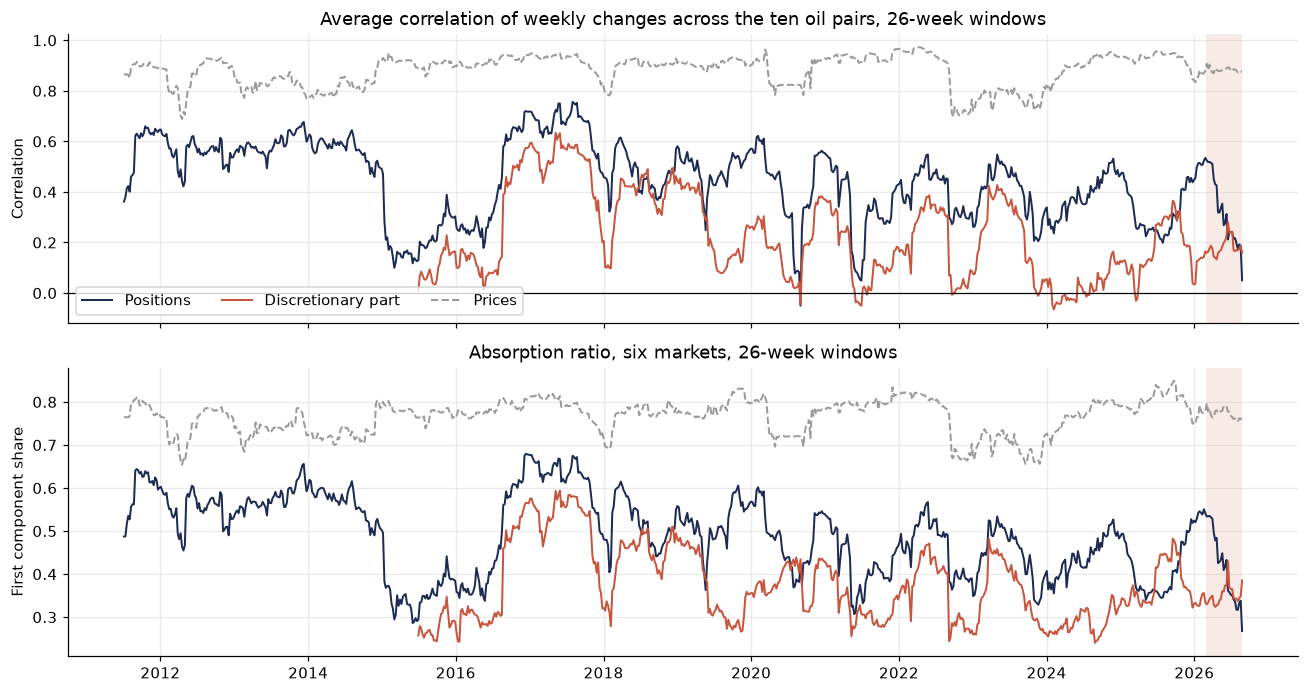

In [4]:
WINDOW = 26
roll = {'Positions': P.rolling_corr(changes, WINDOW),
        'Discretionary part': P.rolling_corr(discretionary, WINDOW),
        'Prices': P.rolling_corr(returns, WINDOW)}
average = pd.DataFrame({name: r[OIL_PAIRS].mean(axis=1) for name, r in roll.items()})
absorption = pd.DataFrame({'Positions': P.absorption_ratio(changes, WINDOW),
                           'Discretionary part': P.absorption_ratio(discretionary, WINDOW),
                           'Prices': P.absorption_ratio(returns, WINDOW)})

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6.4), sharex=True)
for name in average:
    ls = '--' if name == 'Prices' else '-'
    ax1.plot(average.index, average[name], color=COLORS[name], lw=1.3, ls=ls, label=name)
    ax2.plot(absorption.index, absorption[name], color=COLORS[name], lw=1.3, ls=ls, label=name)
for ax in (ax1, ax2):
    shade_war(ax)
    ax.grid(alpha=.25)
ax1.axhline(0, color='black', lw=.8)
ax1.set(title='Average correlation of weekly changes across the ten oil pairs, 26-week windows', ylabel='Correlation')
ax2.set(title='Absorption ratio, six markets, 26-week windows', ylabel='First component share')
ax1.legend(ncol=3, loc='lower left')
fig.tight_layout()
fig.savefig(OUTPUT / 'average_correlation.png', dpi=160)

by_year = pd.DataFrame({name: {year: g.corr().to_numpy()[np.triu_indices(5, 1)].mean()
                               for year, g in x[OIL].groupby(x.index.year)}
                        for name, x in [('Positions', changes), ('Discretionary part', discretionary), ('Prices', returns)]})
display(by_year.round(2).T.rename_axis('Average oil-pair correlation by year'))
for name in average:
    s = average[name].dropna()
    print(f"{name}: average oil-pair correlation {s.loc[:'2026-02-24'].iloc[-1]:.2f} on 24 Feb 2026, "
          f"{s.iloc[-1]:.2f} on {s.index[-1]:%d %b %Y}; sample low {s.min():.2f} ({s.idxmin():%b %Y})")
a = absorption['Positions'].dropna()
print(f"Absorption ratio of positions: {a.loc[:'2026-02-24'].iloc[-1]:.2f} on 24 Feb 2026, {a.iloc[-1]:.2f} on "
      f"{a.index[-1]:%d %b %Y}; sample low {a.min():.2f} ({a.idxmin():%b %Y})")

,2011–2019,2020–2025,2026 (34 weeks),Prices 2011–2019,Prices 2026
Correlation of weekly changes,,,,,
WTI–Brent,0.62,0.40,0.16,0.93,0.97
Brent–Gasoil,0.61,0.53,0.40,0.91,0.83
WTI–Gasoil,0.48,0.40,0.13,0.84,0.80
Gasoil–Heating oil,0.73,0.52,0.24,0.96,0.95
WTI–Heating oil,0.38,0.23,0.22,0.89,0.86


,26 weeks to 24 Feb 2026,26 weeks to 25 Aug 2026,sample low,low on
Rolling 26-week correlation of positions,,,,
WTI–Brent,0.55,0.01,0.01,Aug 2026
Brent–Gasoil,0.69,0.21,-0.1,Sep 2020
WTI–Gasoil,0.46,-0.08,-0.08,Aug 2026
Gasoil–Heating oil,0.67,-0.14,-0.14,Aug 2026
WTI–Heating oil,0.43,0.13,-0.25,Jul 2025


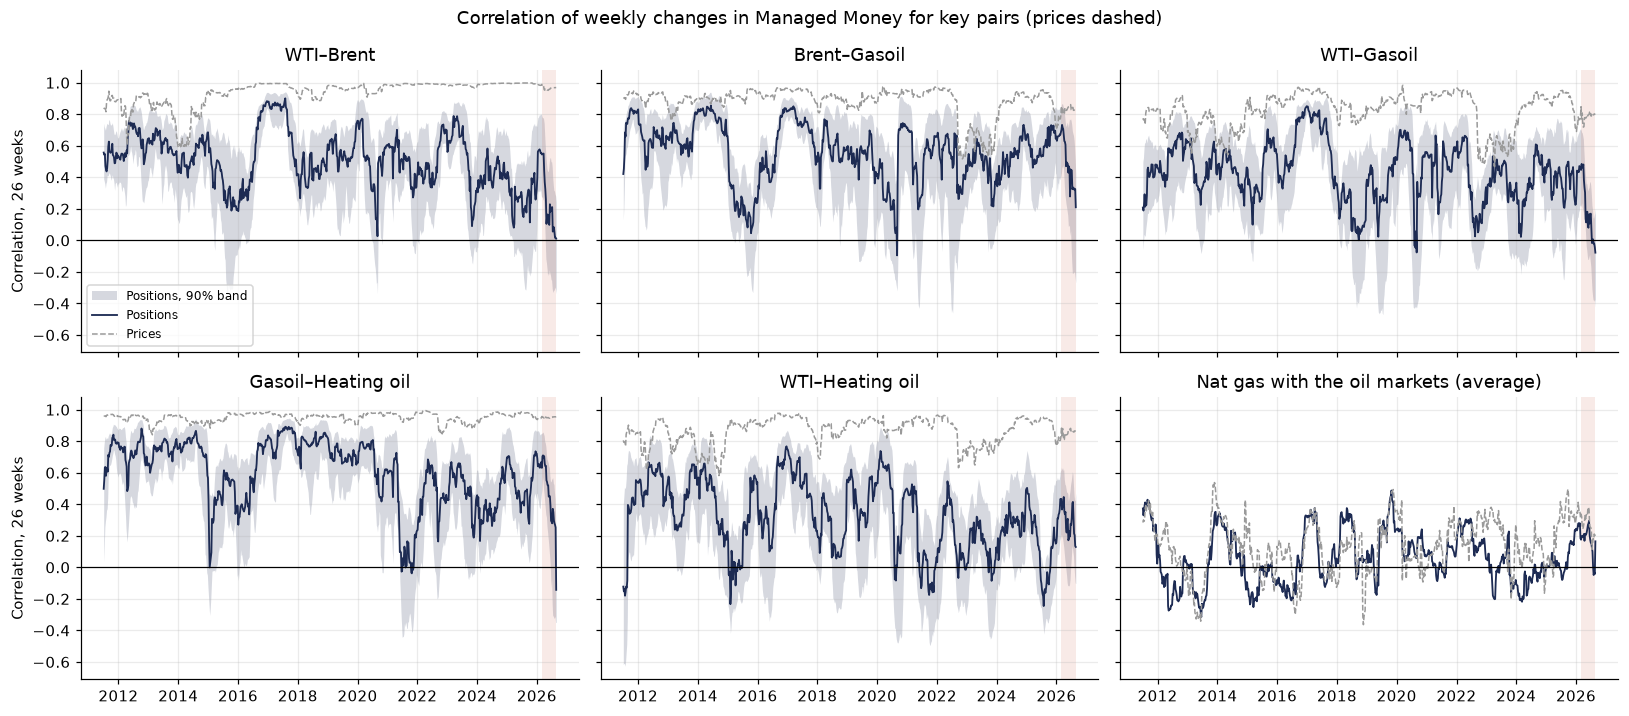

In [5]:
key_pairs = ['WTI-BRENT', 'BRENT-GASOIL', 'WTI-GASOIL', 'GASOIL-HEATOIL', 'WTI-HEATOIL']
bands = {p: P.block_bootstrap_corr(changes[p.split('-')[0]], changes[p.split('-')[1]], WINDOW) for p in key_pairs}

fig, axes = plt.subplots(2, 3, figsize=(15, 6.6), sharex=True, sharey=True)
for ax, p in zip(axes.flat, key_pairs):
    b = bands[p]
    ax.fill_between(b.index, b['low'], b['high'], color=COLORS['Positions'], alpha=.18, lw=0, label='Positions, 90% band')
    ax.plot(b.index, b['corr'], color=COLORS['Positions'], lw=1.2, label='Positions')
    ax.plot(roll['Prices'].index, roll['Prices'][p], color=COLORS['Prices'], lw=1, ls='--', label='Prices')
    ax.set_title(pair_label(p))
ax = axes.flat[5]
gas = [p for p in P.PAIRS if 'NATGAS' in p]
ax.plot(roll['Positions'].index, roll['Positions'][gas].mean(axis=1), color=COLORS['Positions'], lw=1.2)
ax.plot(roll['Prices'].index, roll['Prices'][gas].mean(axis=1), color=COLORS['Prices'], lw=1, ls='--')
ax.set_title('Nat gas with the oil markets (average)')
for ax in axes.flat:
    shade_war(ax)
    ax.axhline(0, color='black', lw=.8)
    ax.grid(alpha=.25)
axes[0, 0].legend(loc='lower left', fontsize=8)
for ax in axes[:, 0]:
    ax.set_ylabel('Correlation, 26 weeks')
fig.suptitle('Correlation of weekly changes in Managed Money for key pairs (prices dashed)')
fig.tight_layout()
fig.savefig(OUTPUT / 'key_pairs.png', dpi=160)

latest = pd.DataFrame({'2011–2019': changes.loc[:'2019'].corr().stack(), '2020–2025': changes.loc['2020':'2025'].corr().stack(),
                       '2026 (34 weeks)': changes.loc['2026'].corr().stack(),
                       'Prices 2011–2019': returns.loc[:'2019'].corr().stack(), 'Prices 2026': returns.loc['2026'].corr().stack()})
latest.index = [pair_label(f'{a}-{b}') for a, b in latest.index]
display(latest.loc[[pair_label(p) for p in key_pairs]].round(2).rename_axis('Correlation of weekly changes'))
extremes = pd.DataFrame({pair_label(p): {'26 weeks to 24 Feb 2026': round(b['corr'].loc[:'2026-02-24'].iloc[-1], 2),
                                         '26 weeks to 25 Aug 2026': round(b['corr'].iloc[-1], 2), 'sample low': round(b['corr'].min(), 2),
                                         'low on': f"{b['corr'].idxmin():%b %Y}"} for p, b in bands.items()}).T
display(extremes.rename_axis('Rolling 26-week correlation of positions'))

**Reading.** Funds have traded the oil complex less and less as one block, while prices stayed as correlated as ever. The average oil-pair correlation of weekly position changes was 0.47–0.63 in every year to 2019 except 2015 (0.23, after the oil price collapse), 0.31–0.41 in 2020–2025 and 0.21 in 2026; for returns it stayed between 0.79 and 0.95.

The war turned that drift into a break. Over 26 weeks, the average fell from 0.53 on 24 February 2026 to 0.05 on 25 August, close to its lowest since 2011 (−0.05 in September 2020), and the absorption ratio of positions halved to 0.27, its lowest since 2011. WTI–Brent (0.55 → 0.01), WTI–Gasoil (0.46 → −0.08) and Gasoil–Heating oil (0.67 → −0.14) all reached their lowest since 2011 in August 2026, although Brent and WTI prices moved together more closely than before (weekly return correlation 0.97 in 2026, 0.93 in 2011–2019). The average for the discretionary part did not fall (0.16 on both dates): the break came from trend following, which stopped moving all oil markets together (see *Anatomy of the 2026 break*).

## Clusters of markets and of periods

**Markets.** In each 26-week window we cluster the six markets into three groups (average linkage on the correlation distance √(2(1 − ρ))). The strips show, week by week, which markets fall in the same group as Brent and as WTI.

**Periods.** We also group the weeks themselves by their fifteen rolling pairwise correlations (k-means, number of regimes chosen by silhouette), to see whether the market switches between distinct correlation regimes.

,WTI,Gasoil,Heating oil,RBOB,Nat gas
Share of weeks in the same group as Brent,,,,,
2011–2019,0.59,0.71,0.66,0.44,0.01
2020–2025,0.60,0.70,0.42,0.58,0.02
2026,0.09,0.71,0.68,0.71,0.00


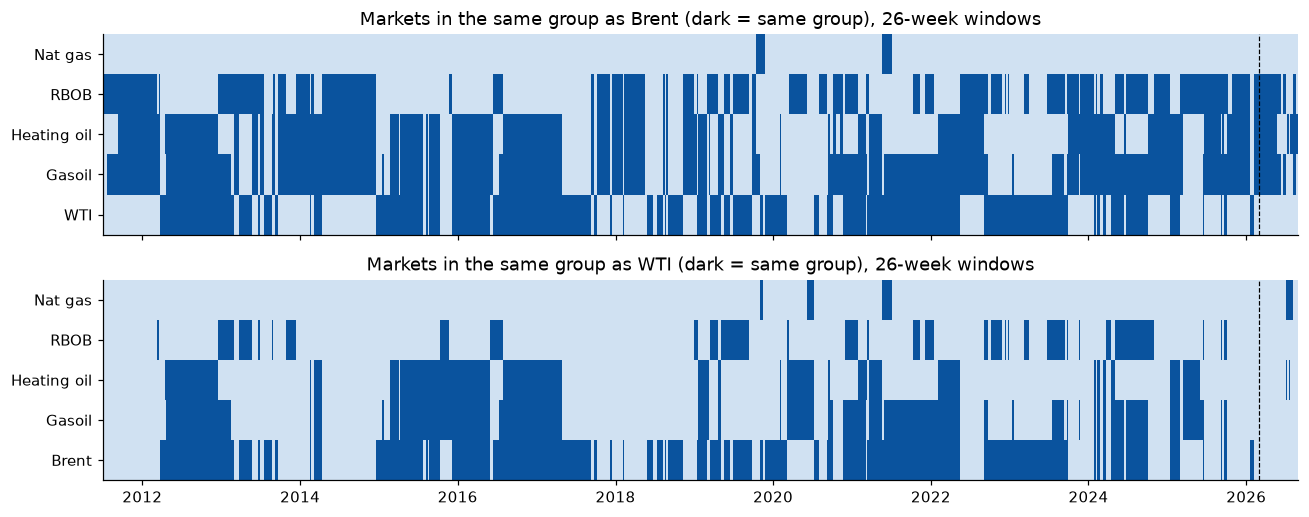

In [6]:
co = P.co_clustering(roll['Positions'], k=3)
fig, axes = plt.subplots(2, 1, figsize=(12, 4.8), sharex=True)
for ax, anchor in zip(axes, ['BRENT', 'WTI']):
    others = [m for m in P.MARKETS if m != anchor]
    grid = np.array([co[pair(anchor, o)].to_numpy() for o in others])
    ax.pcolormesh(co.index, np.arange(len(others)), grid, cmap='Blues', vmin=-.3, vmax=1.2, shading='nearest')
    ax.set_yticks(range(len(others)), [P.LABELS[o] for o in others])
    ax.set_title(f'Markets in the same group as {P.LABELS[anchor]} (dark = same group), 26-week windows')
    ax.axvline(WAR_START, color='black', lw=.8, ls='--')
fig.tight_layout()
fig.savefig(OUTPUT / 'co_clustering.png', dpi=160)
share = pd.DataFrame({P.LABELS[o]: {'2011–2019': co[pair('BRENT', o)].loc[:'2019'].mean(), '2020–2025': co[pair('BRENT', o)].loc['2020':'2025'].mean(),
                                    '2026': co[pair('BRENT', o)].loc['2026'].mean()} for o in P.MARKETS if o != 'BRENT'})
display(share.round(2).rename_axis('Share of weeks in the same group as Brent'))

Silhouette by number of regimes: {2: 0.26, 3: 0.2, 4: 0.18, 5: 0.2}
Regime spells since 2025: [('2024-10-08', 1, 17), ('2025-02-04', 2, 38), ('2025-10-28', 1, 26), ('2026-04-28', 2, 3), ('2026-05-19', 1, 1), ('2026-05-26', 2, 14)]


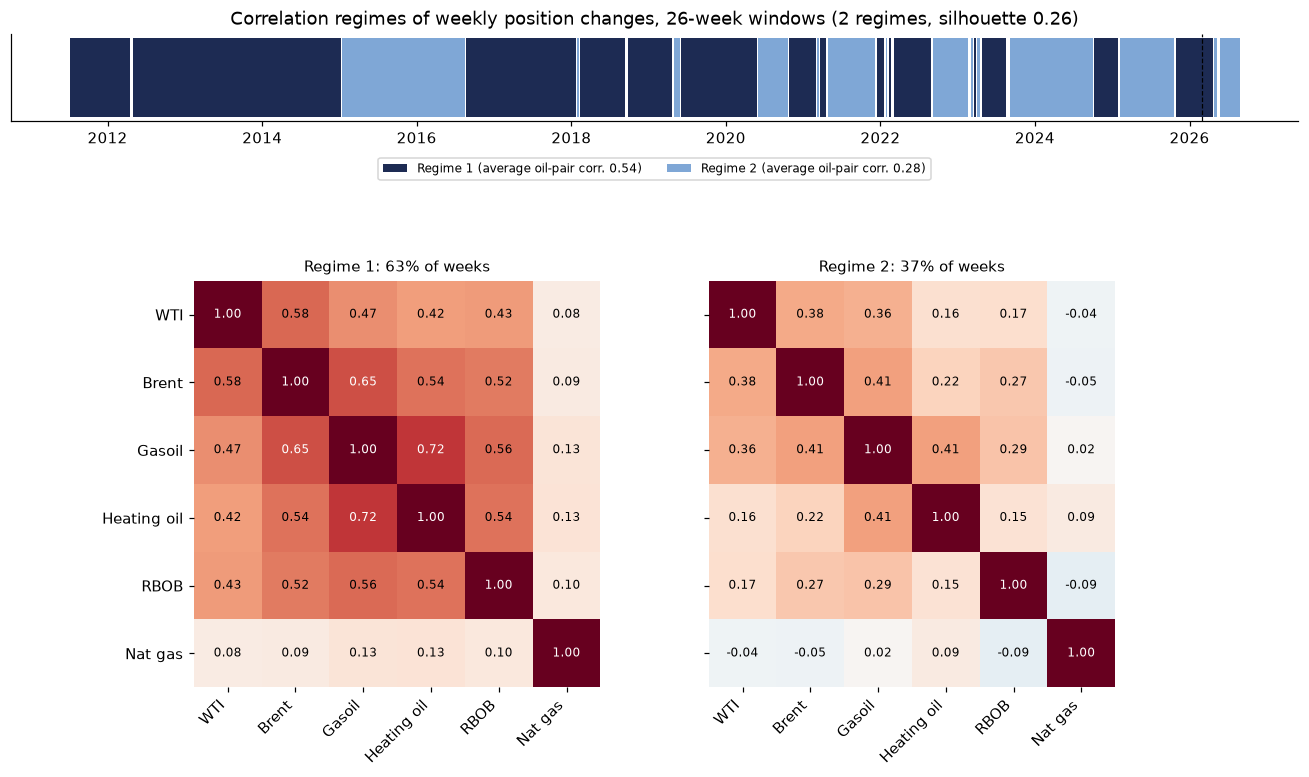

In [7]:
regimes, centers, scores = P.correlation_regimes(roll['Positions'])
k = len(centers)
fig = plt.figure(figsize=(13, 6.6))
top = fig.add_axes([.05, .82, .9, .12])
for r in centers.index:
    top.fill_between(regimes.index, 0, 1, where=regimes.eq(r).to_numpy(), step='mid', color=REGIME_COLORS[r - 1],
                     lw=0, label=f'Regime {r} (average oil-pair corr. {centers.loc[r, OIL_PAIRS].mean():.2f})')
top.axvline(WAR_START, color='black', lw=.8, ls='--')
top.set_yticks([])
top.set_title(f'Correlation regimes of weekly position changes, 26-week windows ({k} regimes, silhouette {scores.max():.2f})')
top.legend(ncol=k, loc='upper center', bbox_to_anchor=(.5, -.35), fontsize=8)
width = min(.9 / k - .04, .3)
left = (1 - k * width - (k - 1) * .06) / 2
for i, r in enumerate(centers.index):
    ax = fig.add_axes([left + i * (width + .06), .04, width, .56])
    heatmap(ax, P.pairs_to_matrix(centers.loc[r]), f'Regime {r}: {regimes.eq(r).mean():.0%} of weeks')
    if i:
        ax.set_yticklabels([])
fig.savefig(OUTPUT / 'regimes.png', dpi=160, bbox_inches='tight')
spells = (regimes != regimes.shift()).cumsum()
runs = regimes.groupby(spells).agg(['first', 'size'])
print('Silhouette by number of regimes:', scores.round(2).to_dict())
print('Regime spells since 2025:', [(f'{regimes.index[spells == s][0]:%Y-%m-%d}', int(r), int(n))
                                    for s, (r, n) in runs.iterrows() if regimes.index[spells == s][-1] >= pd.Timestamp('2025-01-01')])

**Reading.** Normally WTI sits with Brent: they shared a group in 59–60% of 26-week windows in 2011–2025. In 2026 they did so in 9%: Brent stayed with the products (Gasoil 71%, Heating oil 68%, RBOB 71% of windows) and WTI was left in a group of its own, apart from a few weeks with natural gas in July.

The time clustering separates a high-co-movement regime (average oil-pair correlation 0.54, 63% of weeks) from a low one (0.28, 37%). The silhouette is low (0.26), so the two regimes are ends of a continuum rather than sharply distinct states, but the timeline is clear: low-co-movement spells became more frequent after 2020, and the war moved the market into the low regime from 28 April 2026, once most of the 26-week window covered war weeks, where it stayed to the end of the data apart from one week.

## 2026: the Strait of Hormuz crisis

We zoom into July 2025 – August 2026 with 13-week windows. With so few weeks, a correlation needs to be above about 0.5 in absolute value to stand out from zero; the shaded bands are 90% moving-block bootstrap intervals (blocks of four weeks).

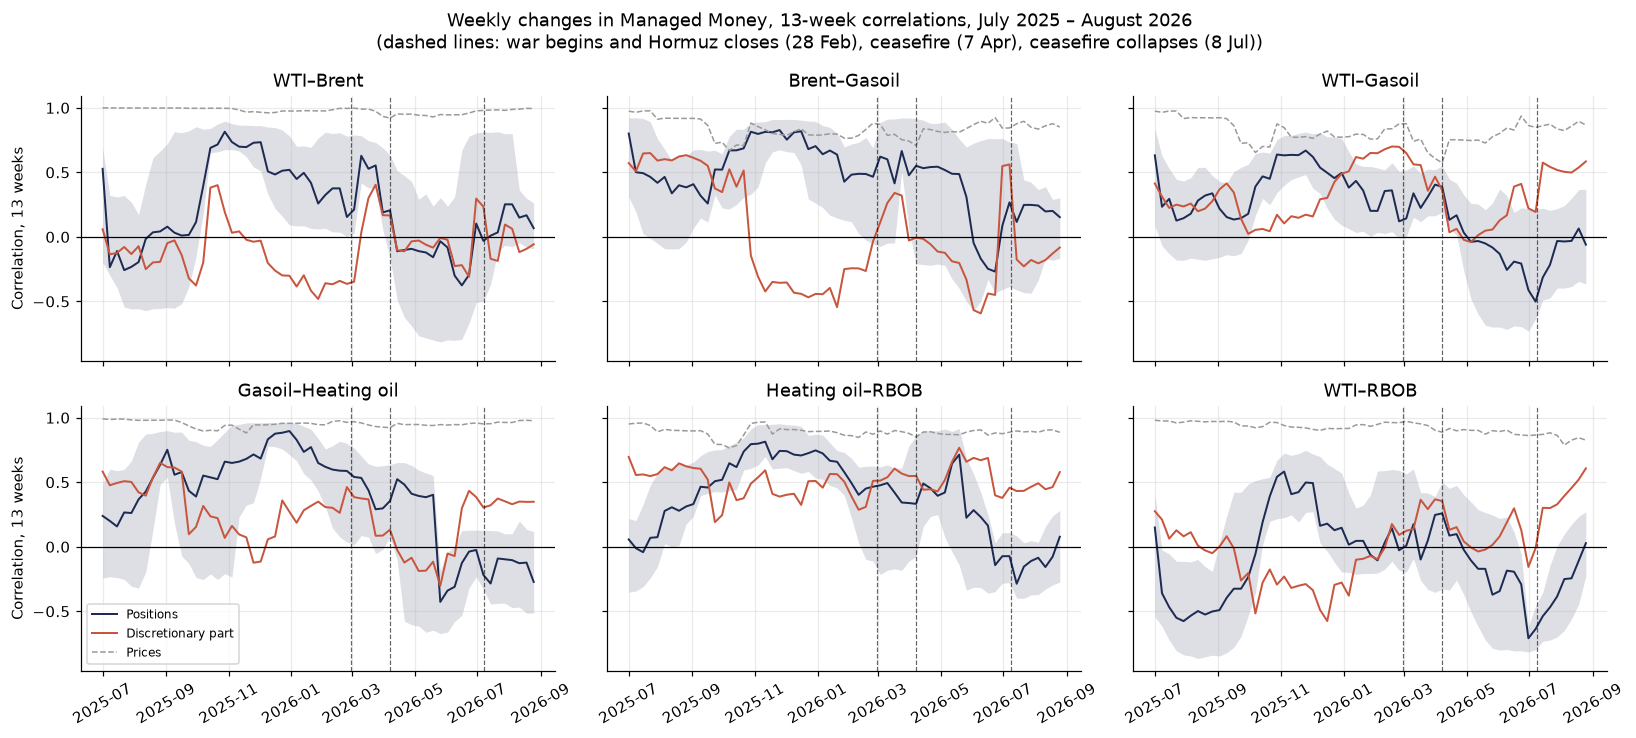

In [8]:
SHORT = 13
ZOOM = ('2025-07-01', '2026-08-31')
zoom_pairs = ['WTI-BRENT', 'BRENT-GASOIL', 'WTI-GASOIL', 'GASOIL-HEATOIL', 'HEATOIL-RBOB', 'WTI-RBOB']
short = {name: P.rolling_corr(x, SHORT) for name, x in [('Positions', changes), ('Discretionary part', discretionary), ('Prices', returns)]}
fig, axes = plt.subplots(2, 3, figsize=(15, 6.8), sharex=True, sharey=True)
for ax, p in zip(axes.flat, zoom_pairs):
    a, b = p.split('-')
    band = P.block_bootstrap_corr(changes[a], changes[b], SHORT).loc[ZOOM[0]:ZOOM[1]]
    ax.fill_between(band.index, band['low'], band['high'], color=COLORS['Positions'], alpha=.15, lw=0)
    for name, s in short.items():
        s = s.loc[ZOOM[0]:ZOOM[1], p]
        ax.plot(s.index, s, color=COLORS[name], lw=1.3 if name != 'Prices' else 1, ls='--' if name == 'Prices' else '-', label=name)
    ax.axhline(0, color='black', lw=.8)
    mark_events(ax)
    ax.set_title(pair_label(p))
    ax.grid(alpha=.25)
axes[1, 0].legend(loc='lower left', fontsize=8)
for ax in axes[:, 0]:
    ax.set_ylabel('Correlation, 13 weeks')
for ax in axes[1]:
    ax.tick_params(axis='x', rotation=30)
fig.suptitle(f'Weekly changes in Managed Money, 13-week correlations, July 2025 – August 2026\n({EVENT_NOTE})')
fig.tight_layout()
fig.savefig(OUTPUT / 'zoom_2026_pairs.png', dpi=160)

Pre-war  \
pair            series                                     
WTI–Brent       Positions           +0.55 [+0.24, +0.82]   
                Discretionary part  -0.17 [-0.51, +0.22]   
Brent–Gasoil    Positions           +0.69 [+0.39, +0.84]   
                Discretionary part  -0.21 [-0.53, +0.18]   
WTI–Gasoil      Positions           +0.46 [+0.15, +0.71]   
                Discretionary part  +0.49 [+0.27, +0.68]   
WTI–Heating oil Positions           +0.43 [+0.17, +0.66]   
                Discretionary part  +0.18 [-0.16, +0.47]   
Gasoil–RBOB     Positions           +0.68 [+0.48, +0.81]   
                Discretionary part  +0.34 [-0.02, +0.60]   

                                        War to ceasefire  \
pair            series                                     
WTI–Brent       Positions           -0.14 [-0.97, +0.72]   
                Discretionary part  -0.02 [-0.74, +0.65]   
Brent–Gasoil    Positions           +0.45 [-1.00, +0.92]   
                Discretionary part  -0.36 [-1.00, +0.97]   
WTI–Gasoil      Positions           +0.32 [+0.18, +0.95]   
                Discretionary part  +0.35 [-0.52, +0.89]   
WTI–Heating oil Positions           -0.18 [-0.88, +0.21]   
                Discretionary part  +0.25 [-1.00, +0.66]   
Gasoil–RBOB     Positions           -0.35 [-0.97, +0.17]   
                Discretionary part  -0.23 [-0.95, +0.37]   

                                               Ceasefire        After collapse  
pair            series                                                          
WTI–Brent       Positions           -0.03 [-0.61, +0.75]  -0.09 [-0.63, +0.69]  
                Discretionary part  +0.23 [-0.05, +0.63]  +0.00 [-0.92, +0.91]  
Brent–Gasoil    Positions           +0.27 [-0.29, +0.71]  +0.28 [-0.40, +0.92]  
                Discretionary part  +0.56 [+0.18, +0.83]  -0.24 [-0.69, +0.78]  
WTI–Gasoil      Positions           -0.50 [-0.72, +0.09]  +0.38 [-0.05, +0.84]  
                Discretionary part  +0.19 [-0.32, +0.70]  +0.53 [-0.40, +0.77]  
WTI–Heating oil Positions           +0.54 [+0.27, +0.76]  -0.54 [-0.90, +0.33]  
                Discretionary part  +0.76 [+0.61, +0.88]  -0.50 [-0.97, +0.71]  
Gasoil–RBOB     Positions           +0.26 [-0.23, +0.62]  +0.25 [-0.27, +1.00]  
                Discretionary part  +0.50 [+0.12, +0.72]  +0.73 [-0.32, +0.99]

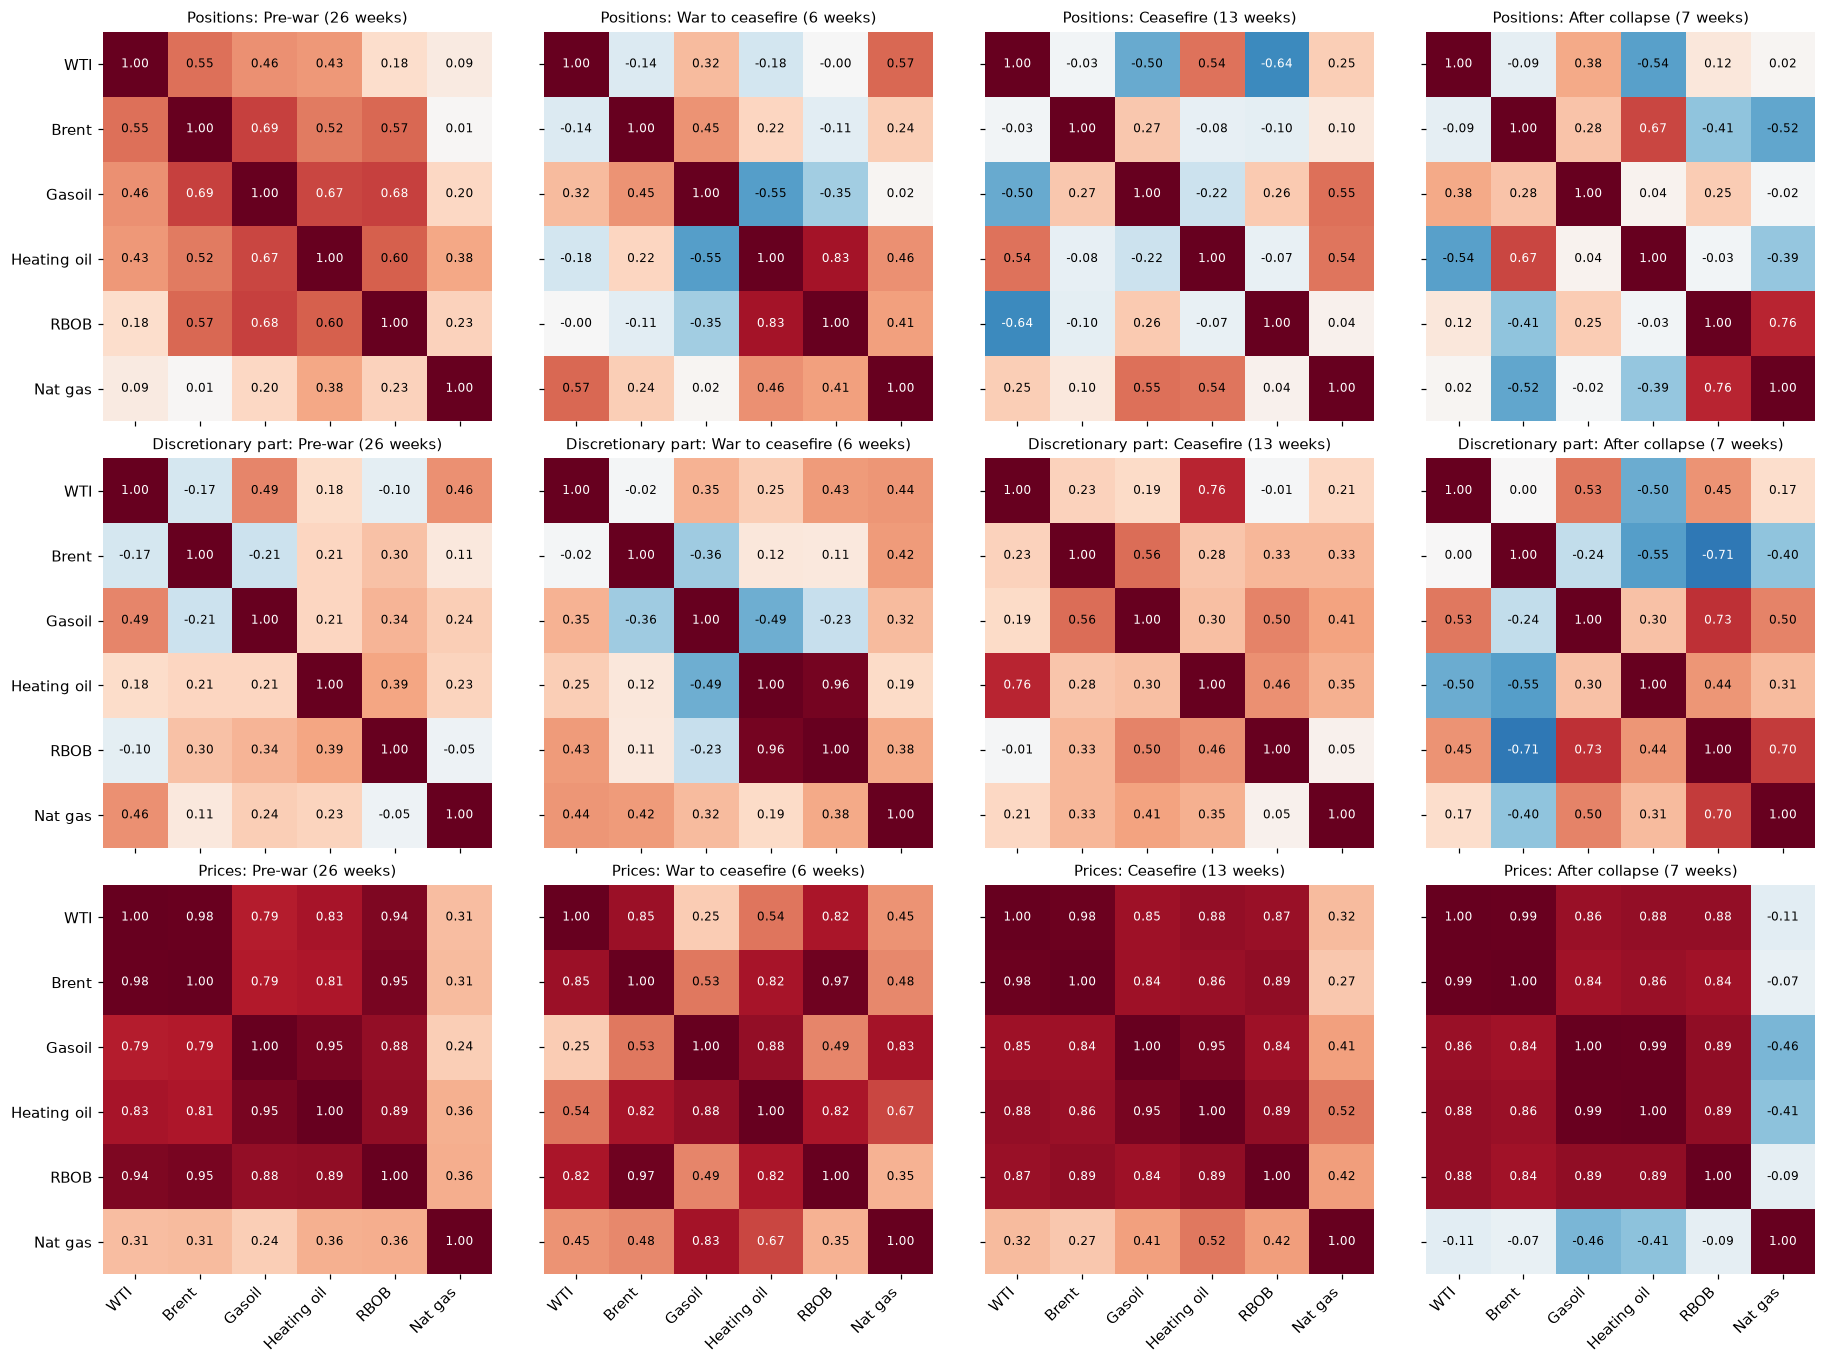

In [9]:
phases = {name: (s, e) for name, (s, e) in P.PHASES.items()}
weeks = {name: len(changes.loc[s:e]) for name, (s, e) in phases.items()}
fig, axes = plt.subplots(3, 4, figsize=(17, 12.5))
for row, (label, x) in enumerate([('Positions', changes), ('Discretionary part', discretionary), ('Prices', returns)]):
    for col, (name, corr) in enumerate(P.phase_corr(x).items()):
        heatmap(axes[row, col], corr, f'{label}: {name} ({weeks[name]} weeks)')
        if col:
            axes[row, col].set_yticklabels([])
        if row < 2:
            axes[row, col].set_xticklabels([])
fig.tight_layout()
fig.savefig(OUTPUT / 'phase_matrices.png', dpi=160)

rows = {}
for p in ['WTI-BRENT', 'BRENT-GASOIL', 'WTI-GASOIL', 'WTI-HEATOIL', 'GASOIL-RBOB']:
    a, b = p.split('-')
    for label, x in [('Positions', changes), ('Discretionary part', discretionary)]:
        by_phase_ci = {}
        for name, (s, e) in phases.items():
            seg = x.loc[s:e]
            band = P.block_bootstrap_corr(seg[a], seg[b], len(seg), block=2).iloc[0]
            by_phase_ci[name] = f"{band['corr']:+.2f} [{band['low']:+.2f}, {band['high']:+.2f}]"
        rows[(pair_label(p), label)] = by_phase_ci
display(pd.DataFrame(rows).T.rename_axis(['pair', 'series']))

In [10]:
own = pd.concat({'Positions vs own return': P.own_return_corr(changes, returns),
                 'Trend part vs own return': P.own_return_corr(trend_part, returns.loc['2015':]),
                 'Discretionary part vs own return': P.own_return_corr(discretionary, returns.loc['2015':])})
own = own.rename(index=P.LABELS, level=1)
display(own.round(2))
size = pd.concat({'Trend part': trend_part, 'Discretionary part': discretionary}, axis=1)
size_by_phase = pd.DataFrame({name: size.loc[s:e].std() for name, (s, e) in phases.items()}).div(1e3)
size_by_phase.index = pd.MultiIndex.from_tuples([(a, P.LABELS[b]) for a, b in size_by_phase.index])
display(size_by_phase.round(1).rename_axis(['Std of weekly change (k contracts)', 'market']))

Pre-war  War to ceasefire  \
                                 market                                   
Positions vs own return          WTI             0.59              0.19   
                                 Brent           0.81              0.03   
                                 Gasoil          0.73             -0.80   
                                 Heating oil     0.64              0.72   
                                 RBOB            0.67              0.83   
                                 Nat gas         0.59              0.08   
Trend part vs own return         WTI             0.94             -0.84   
                                 Brent           0.91             -0.76   
                                 Gasoil          0.88             -0.86   
                                 Heating oil     0.82             -0.73   
                                 RBOB            0.95             -0.73   
                                 Nat gas         0.89              0.89   
Discretionary part vs own return WTI            -0.57              0.45   
                                 Brent           0.34              0.21   
                                 Gasoil         -0.51             -0.18   
                                 Heating oil     0.21              0.83   
                                 RBOB            0.03              0.92   
                                 Nat gas        -0.33             -0.24   

                                              Ceasefire  After collapse  
                                 market                                  
Positions vs own return          WTI              -0.17           -0.54  
                                 Brent             0.86            0.76  
                                 Gasoil            0.46            0.28  
                                 Heating oil       0.15            0.83  
                                 RBOB              0.03            0.19  
                                 Nat gas           0.76            0.80  
Trend part vs own return         WTI               0.82            0.88  
                                 Brent             0.89            0.88  
                                 Gasoil            0.67            0.87  
                                 Heating oil       0.72            0.91  
                                 RBOB              0.76            0.91  
                                 Nat gas           0.97            0.96  
Discretionary part vs own return WTI              -0.60           -0.88  
                                 Brent            -0.04            0.33  
                                 Gasoil           -0.23           -0.66  
                                 Heating oil      -0.36           -0.29  
                                 RBOB             -0.37           -0.59  
                                 Nat gas           0.51            0.61

Pre-war  War to ceasefire  \
Std of weekly change (k contracts) market                                   
Trend part                         WTI             21.1               5.5   
                                   Brent           29.8              10.0   
                                   Gasoil          18.8               7.2   
                                   Heating oil      5.1               2.3   
                                   RBOB             6.8               4.9   
                                   Nat gas         25.0               5.0   
Discretionary part                 WTI             16.4              16.3   
                                   Brent           26.1              42.9   
                                   Gasoil           9.4               8.5   
                                   Heating oil      6.4               4.6   
                                   RBOB             7.7               7.7   
                                   Nat gas         20.5              13.8   

                                                Ceasefire  After collapse  
Std of weekly change (k contracts) market                                  
Trend part                         WTI               10.1             9.6  
                                   Brent             16.4            20.3  
                                   Gasoil             7.4             7.8  
                                   Heating oil        2.0             2.8  
                                   RBOB               2.2             3.6  
                                   Nat gas            7.9            10.1  
Discretionary part                 WTI               17.9            17.5  
                                   Brent              8.0            22.8  
                                   Gasoil             9.2             8.3  
                                   Heating oil        2.9             1.4  
                                   RBOB               4.2             4.3  
                                   Nat gas           16.6            16.6

,War to ceasefire,Ceasefire,After collapse
Discretionary change by phase (million barrels),,,
WTI,10.2,65.0,-32.4
Brent,68.8,-140.2,19.5
Gasoil,-22.8,34.6,-12.3
Heating oil,-5.1,-2.7,2.6
RBOB,-31.4,25.5,-1.0


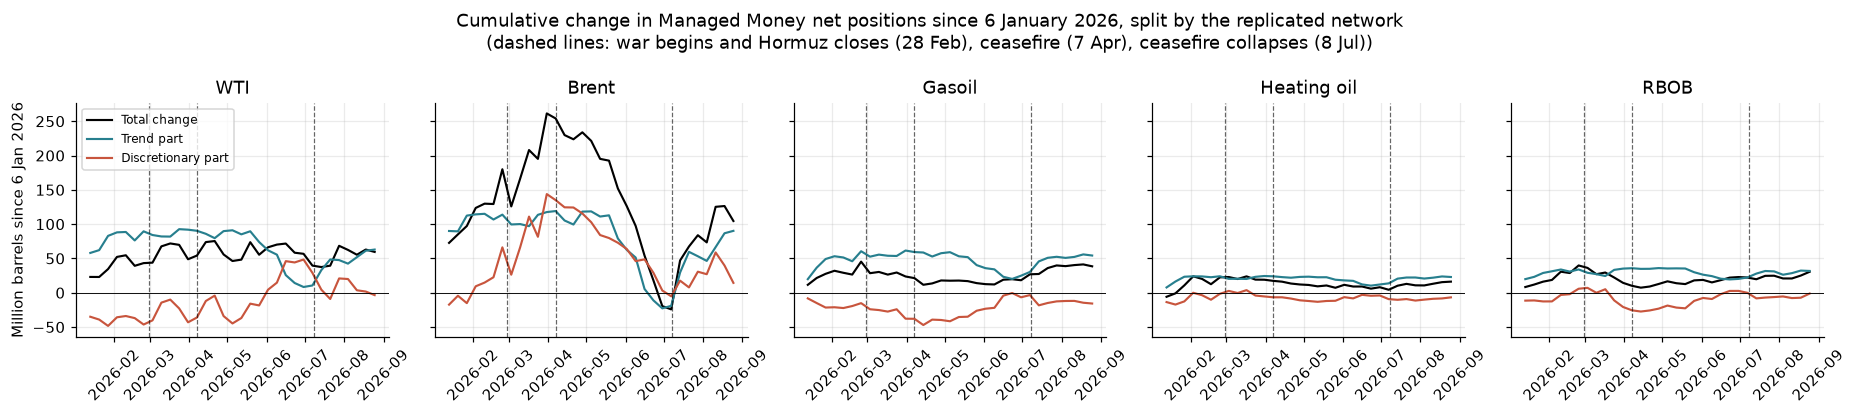

In [11]:
since = pd.Timestamp('2026-01-06')
parts = {'Total change': nn['actual'], 'Trend part': nn['trend'], 'Discretionary part': nn['discretionary']}
fig, axes = plt.subplots(1, 5, figsize=(17, 3.8), sharey=True)
for ax, m in zip(axes, OIL):
    for name, x in parts.items():
        cum = x.loc[since:, m].iloc[1:].cumsum() * P.BARRELS[m] / 1e6
        ax.plot(cum.index, cum, lw=1.4, color={'Total change': 'black', 'Trend part': COLORS['Trend part'],
                                                'Discretionary part': COLORS['Discretionary part']}[name], label=name)
    ax.axhline(0, color='black', lw=.6)
    mark_events(ax)
    ax.set_title(P.LABELS[m])
    ax.tick_params(axis='x', rotation=45)
    ax.grid(alpha=.25)
axes[0].set_ylabel('Million barrels since 6 Jan 2026')
axes[0].legend(fontsize=8, loc='upper left')
fig.suptitle(f'Cumulative change in Managed Money net positions since 6 January 2026, split by the replicated network\n({EVENT_NOTE})')
fig.tight_layout()
fig.savefig(OUTPUT / 'cumulative_2026_split.png', dpi=160)
cum_table = pd.DataFrame({name: {P.LABELS[m]: x.loc[s:e, m].sum() * P.BARRELS[m] / 1e6 for m in OIL}
                          for name, (s, e) in phases.items() for x in [nn['discretionary']] if name != 'Pre-war'})
display(cum_table.round(1).rename_axis('Discretionary change by phase (million barrels)'))

**Reading.** The phases are short (6, 13 and 7 weeks), so single correlations are imprecise; the bootstrap intervals show which ones stand out. Four results are robust enough to read.

- **Before the war, positions moved as one block and followed prices.** Over September 2025 – February 2026, WTI–Brent position changes correlated 0.55 [0.24, 0.82] and Brent–Gasoil 0.69, and every market's positions tracked its own price (0.59–0.81, Brent 0.81): the OIES comment's benchmark ("exceeded 50% across all five markets and approached 80% for Brent").
- **In the first weeks of the war the link to prices broke, and Brent's moves were mostly discretionary.** Between the outbreak and the ceasefire, positions no longer tracked prices in WTI (0.19), Brent (0.03) or Gasoil (−0.80); only Heating oil (0.72) and RBOB (0.83) still did. Brent's discretionary part swung by 42.9k contracts a week (10.0k for its trend part) and added 68.8 million barrels of length: the comment's bullish discretionary positioning concentrated in crude. The comment finds the price link survived in Brent and Heating oil; with six weeks we cannot settle the difference. In the oil markets the network's trend part moved against the week's return in this phase (−0.73 to −0.86), probably because the jump in volatility cut its volatility-scaled momentum inputs even as prices rose.
- **From the ceasefire, trend following went through Brent, not WTI.** Brent's positions tracked its price again (0.86 during the ceasefire, 0.76 after the collapse) while WTI's did not (−0.17, −0.54), and WTI–Brent position changes were uncorrelated (−0.03, −0.09). The network's trend part shrank more in WTI (from 21.1k to about 10k contracts a week) than in Brent (from 29.8k to 16–20k), though not to the near zero the comment reports with its own model.
- **Discretionary length rotated from Brent to WTI and the products.** During the ceasefire, discretionary positions fell by 140.2 million barrels in Brent and rose in WTI (+65.0), Gasoil (+34.6) and RBOB (+25.5), as in the comment's rotation toward refined products from April. These discretionary moves were shared: WTI's moved with Heating oil's (0.76 [0.61, 0.88]) and Gasoil's with RBOB's (0.50 [0.12, 0.72]). After the collapse the network shows Gasoil's discretionary length falling (−12.3 million barrels), where the comment finds it rising further in July.

## Anatomy of the 2026 break

Three questions about the fall in co-movement: which markets broke away, whether it came from the trend or the discretionary part of positions, and how it compares with the earlier breaks since 2011. All windows are 26 weeks.

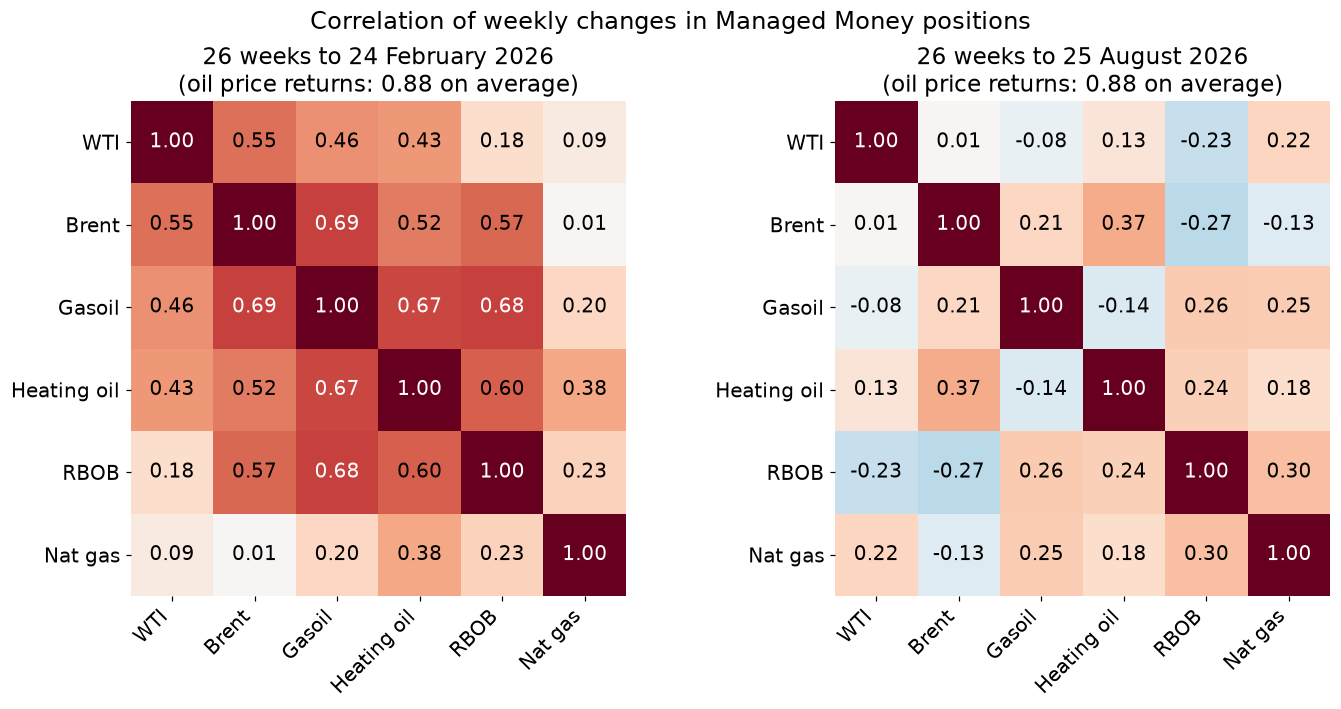

,24 Feb 2026,25 Aug 2026,change
26-week correlation of positions,,,
Brent–RBOB,0.57,-0.27,-0.84
Gasoil–Heating oil,0.67,-0.14,-0.81
WTI–Brent,0.55,0.01,-0.54
WTI–Gasoil,0.46,-0.08,-0.54
Brent–Gasoil,0.69,0.21,-0.48
Gasoil–RBOB,0.68,0.26,-0.42
WTI–RBOB,0.18,-0.23,-0.41
Heating oil–RBOB,0.60,0.24,-0.36
WTI–Heating oil,0.43,0.13,-0.30


In [12]:
windows = {'26 weeks to 24 February 2026': changes.loc[:'2026-02-24'].iloc[-WINDOW:],
           '26 weeks to 25 August 2026': changes.iloc[-WINDOW:]}
upper = np.triu(np.ones((6, 6), dtype=bool), 1)
price_avg = {name: returns.loc[x.index, OIL].corr().to_numpy()[np.triu_indices(5, 1)].mean() for name, x in windows.items()}
with plt.rc_context({'font.size': 13}):
    fig, axes = plt.subplots(1, 2, figsize=(13, 6.4))
    for ax, (name, x) in zip(axes, windows.items()):
        heatmap(ax, x.corr(), f'{name}\n(oil price returns: {price_avg[name]:.2f} on average)', fontsize=13)
    fig.suptitle('Correlation of weekly changes in Managed Money positions', fontsize=16)
    fig.tight_layout()
    fig.savefig(OUTPUT / 'matrices_before_after.png', dpi=160)
plt.show()
before, after = (x.corr().where(upper).stack() for x in windows.values())
falls = pd.DataFrame({'24 Feb 2026': before, '25 Aug 2026': after, 'change': after - before}).sort_values('change')
falls.index = [pair_label(f'{a}-{b}') for a, b in falls.index]
display(falls.round(2).rename_axis('26-week correlation of positions'))

2015–2025 average  24 Feb  7 Apr  \
With the other oil markets WTI                       0.38    0.41   0.30   
                           Brent                     0.44    0.58   0.46   
                           Gasoil                    0.48    0.62   0.57   
                           Heating oil               0.39    0.55   0.50   
                           RBOB                      0.36    0.51   0.42   
With own trend part        WTI                       0.69    0.66   0.56   
                           Brent                     0.67    0.82   0.73   
                           Gasoil                    0.70    0.87   0.84   
                           Heating oil               0.53    0.68   0.63   
                           RBOB                      0.60    0.63   0.53   

                                        7 Jul  25 Aug  
With the other oil markets WTI           0.15   -0.04  
                           Brent         0.25    0.08  
                           Gasoil        0.32    0.06  
                           Heating oil   0.27    0.15  
                           RBOB          0.21    0.00  
With own trend part        WTI           0.34   -0.02  
                           Brent         0.68    0.70  
                           Gasoil        0.62    0.24  
                           Heating oil   0.26    0.31  
                           RBOB          0.25   -0.15

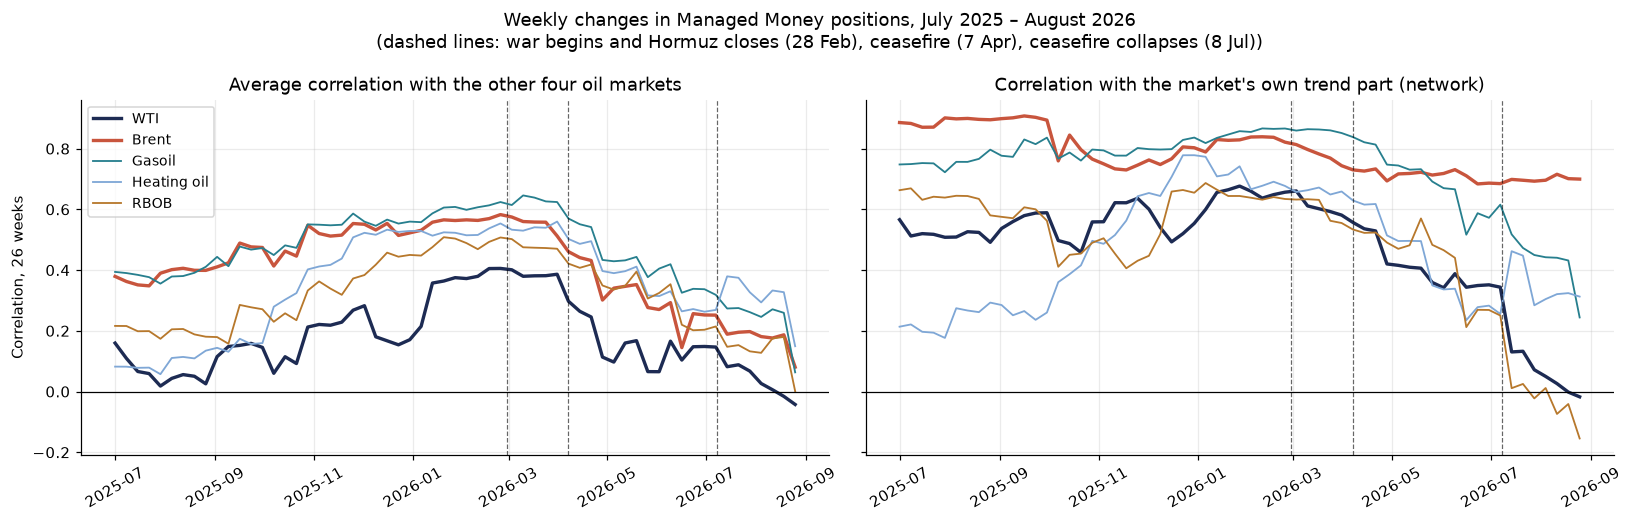

In [13]:
ZOOM_26 = ('2025-07-01', '2026-08-31')
by_market = P.market_average(roll['Positions'], OIL)
follows = nn['actual'][OIL].rolling(WINDOW).corr(nn['trend'][OIL])
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), sharey=True)
for ax, (title, x) in zip(axes, [('Average correlation with the other four oil markets', by_market),
                                 ("Correlation with the market's own trend part (network)", follows)]):
    for m in OIL:
        s = x.loc[ZOOM_26[0]:ZOOM_26[1], m]
        ax.plot(s.index, s, color=COLORS[m], lw=2.2 if m in ('WTI', 'BRENT') else 1.2, label=P.LABELS[m])
    ax.axhline(0, color='black', lw=.8)
    mark_events(ax)
    ax.set_title(title)
    ax.grid(alpha=.25)
    ax.tick_params(axis='x', rotation=30)
axes[0].set_ylabel('Correlation, 26 weeks')
axes[0].legend(fontsize=9, loc='upper left')
fig.suptitle(f'Weekly changes in Managed Money positions, July 2025 – August 2026\n({EVENT_NOTE})')
fig.tight_layout()
fig.savefig(OUTPUT / 'who_broke_away.png', dpi=160)

DATES = {'24 Feb': '2026-02-24', '7 Apr': '2026-04-07', '7 Jul': '2026-07-07', '25 Aug': '2026-08-25'}
at_dates = lambda x: pd.DataFrame({'2015–2025 average': x.loc['2015':'2025'].mean(),
                                   **{d: x.loc[:v].iloc[-1] for d, v in DATES.items()}})
display(pd.concat({'With the other oil markets': at_dates(by_market), 'With own trend part': at_dates(follows)})
        .rename(index=P.LABELS, level=1).round(2))

,Trend-following term,Rest (discretionary),Cross term,Average oil-pair correlation,Correlation of trend parts,Correlation of discretionary parts,"Slope on own trend part, WTI","Slope on own trend part, Brent","Slope on own trend part, Gasoil","Slope on own trend part, Heating oil","Slope on own trend part, RBOB"
"Oil markets, 26 weeks",,,,,,,,,,,
2015–2025 average,0.36,0.10,-0.04,0.42,0.86,0.23,1.27,1.10,1.14,1.17,1.28
24 Feb,0.45,0.09,-0.00,0.53,0.84,0.16,0.55,1.22,0.74,1.14,0.93
7 Apr,0.36,0.09,0.00,0.45,0.84,0.14,0.45,1.22,0.70,0.95,0.80
7 Jul,0.15,0.11,-0.01,0.24,0.83,0.24,0.30,0.99,0.53,0.41,0.26
25 Aug,0.02,0.02,0.01,0.05,0.83,0.16,-0.02,1.23,0.22,0.36,-0.20


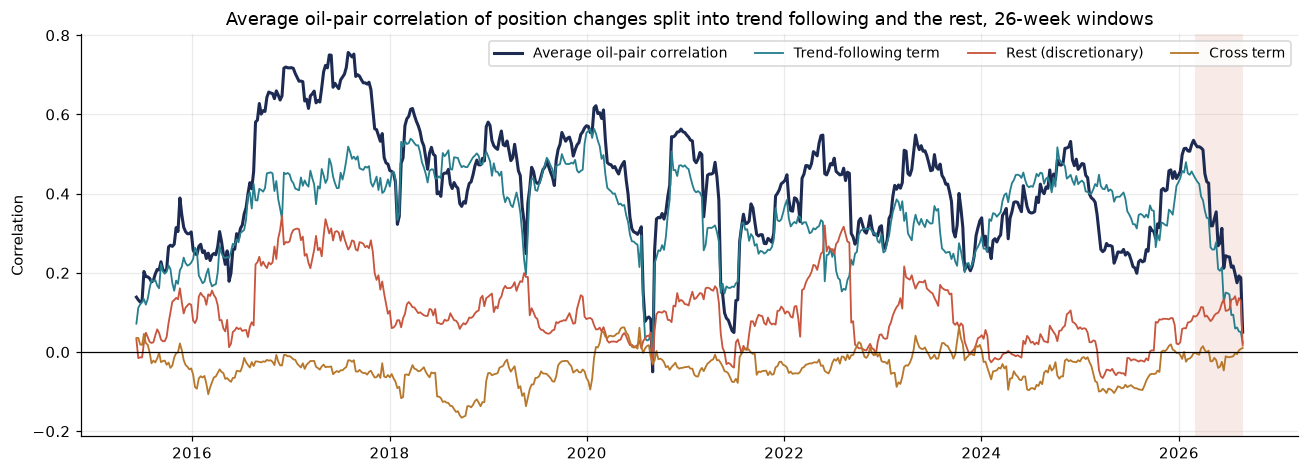

In [14]:
# Each market's change x = beta t + e, with t its trend part; the average oil-pair correlation splits into
# beta_a beta_b cov(t_a, t_b) (trend following), cov(e_a, e_b) (the rest) and a cross term (P.correlation_split).
split = P.correlation_split(nn['actual'][OIL], nn['trend'][OIL], WINDOW, OIL)
split['total'] = split.sum(axis=1, min_count=3)
SPLIT_LABELS = {'total': 'Average oil-pair correlation', 'trend': 'Trend-following term',
                'other': 'Rest (discretionary)', 'cross': 'Cross term'}
fig, ax = plt.subplots(figsize=(12, 4.4))
for name, color in zip(SPLIT_LABELS, [COLORS['Positions'], COLORS['Trend part'], COLORS['Discretionary part'], COLORS['RBOB']]):
    ax.plot(split.index, split[name], color=color, lw=2 if name == 'total' else 1.2, label=SPLIT_LABELS[name])
shade_war(ax)
ax.axhline(0, color='black', lw=.8)
ax.grid(alpha=.25)
ax.set(title='Average oil-pair correlation of position changes split into trend following and the rest, 26-week windows',
       ylabel='Correlation')
ax.legend(ncol=4, fontsize=9, loc='upper right')
fig.tight_layout()
fig.savefig(OUTPUT / 'correlation_split.png', dpi=160)

slopes = P.trend_slopes(nn['actual'][OIL], nn['trend'][OIL], WINDOW).rename(columns=lambda m: f'Slope on own trend part, {P.LABELS[m]}')
parts_corr = {'Correlation of trend parts': P.rolling_corr(nn['trend'][OIL], WINDOW).mean(axis=1),
              'Correlation of discretionary parts': P.rolling_corr(nn['discretionary'][OIL], WINDOW).mean(axis=1)}
table = at_dates(pd.concat([split.rename(columns=SPLIT_LABELS), pd.DataFrame(parts_corr), slopes], axis=1)).T
display(table.round(2).rename_axis('Oil markets, 26 weeks'))

In [15]:
# Spells since 2011 when the average oil-pair correlation fell below 0.2 (dips of one or two weeks left out).
spells = P.low_spells(average['Positions'], 0.2)
spells = spells[spells['weeks'] >= 3].reset_index(drop=True)
display(spells.assign(low=spells['low'].round(2)))
lows = spells['low on']
episodes = pd.DataFrame({f'{d:%b %Y}': {**roll['Positions'].loc[d, OIL_PAIRS].rename(pair_label),
                                        'Average, positions': average['Positions'].loc[d],
                                        'Average, prices': average['Prices'].loc[d],
                                        'Average, trend parts': parts_corr['Correlation of trend parts'].get(d, np.nan),
                                        'Trend-following term': split['trend'].get(d, np.nan),
                                        **{f'{P.LABELS[m]} with own trend part': follows[m].get(d, np.nan) for m in OIL}}
                         for d in lows})
display(episodes.round(2).rename_axis('26-week correlation at each low'))

,start,end,weeks,low on,low
0,2015-02-03,2015-08-18,28,2015-03-03,0.10
1,2020-07-28,2020-09-01,6,2020-09-01,-0.05
2,2021-05-11,2021-07-13,10,2021-06-29,0.05
3,2026-07-28,2026-08-25,5,2026-08-25,0.05


,Mar 2015,Sep 2020,Jun 2021,Aug 2026
26-week correlation at each low,,,,
WTI–Brent,0.33,0.03,0.51,0.01
WTI–Gasoil,0.10,-0.08,0.29,-0.08
WTI–Heating oil,-0.08,0.00,-0.12,0.13
WTI–RBOB,-0.19,-0.29,-0.28,-0.23
Brent–Gasoil,0.34,-0.10,0.29,0.21
Brent–Heating oil,0.21,-0.51,-0.13,0.37
Brent–RBOB,-0.07,0.35,0.02,-0.27
Gasoil–Heating oil,0.28,0.57,-0.02,-0.14
Gasoil–RBOB,0.21,-0.22,-0.19,0.26


**Reading.**

- **Every oil market lost its link with the others, WTI first.** WTI's average correlation with the other four oil markets fell from 0.41 on 24 February to 0.30 at the ceasefire, 0.15 at its collapse and −0.04 on 25 August; the other four held at 0.42–0.57 until the ceasefire and ended at 0.00–0.15. The largest falls are Brent–RBOB (0.57 → −0.27) and Gasoil–Heating oil (0.67 → −0.14).
- **The trend signals still moved together; positions stopped following them, except in Brent.** The network's trend parts stayed as correlated across the oil markets as usual (0.83–0.84 in 2026, 0.86 on average in 2015–2025), because prices did. What changed is how closely positions followed them. From 24 February to 25 August, the slope of each market's weekly change on its own trend part stayed at 1.22–1.23 in Brent but fell from 0.55 to −0.02 in WTI, from 0.93 to −0.20 in RBOB, from 0.74 to 0.22 in Gasoil and from 1.14 to 0.36 in Heating oil. Splitting the average correlation the same way, the trend-following term fell from 0.45 to 0.02 and the rest from 0.09 to 0.02: almost all of the break is trend following that stopped outside Brent.
- **There have been breaks before, but not like this one.** Since 2011 the 26-week average fell below 0.2 for three weeks or more in four spells: February–August 2015 (low 0.10, after the oil price collapse), July–September 2020 (−0.05, after COVID and the negative WTI price), May–July 2021 (0.05) and July–August 2026 (0.05, still open at the end of the data). Prices stayed correlated in all four (0.82–0.91), and so did the trend parts where we have them (0.81–0.91): each break came from positions, not prices. 2026 is the only one in which the crude pair and the distillate pair broke together (WTI–Brent held at 0.33 in 2015 and 0.51 in 2021, Gasoil–Heating oil at 0.28 in 2015 and 0.57 in 2020), and the only one with a single market still following its trend part closely (Brent 0.70, the others −0.15 to 0.31; in 2020 none did, in 2021 the crudes and Gasoil did).


## Brent versus WTI

Brent minus WTI: +12 mb on average 2011–2025, +233 mb on 24 Feb 2026, +309 mb at its 2026 peak (31 Mar), +141 mb on 25 Aug 2026


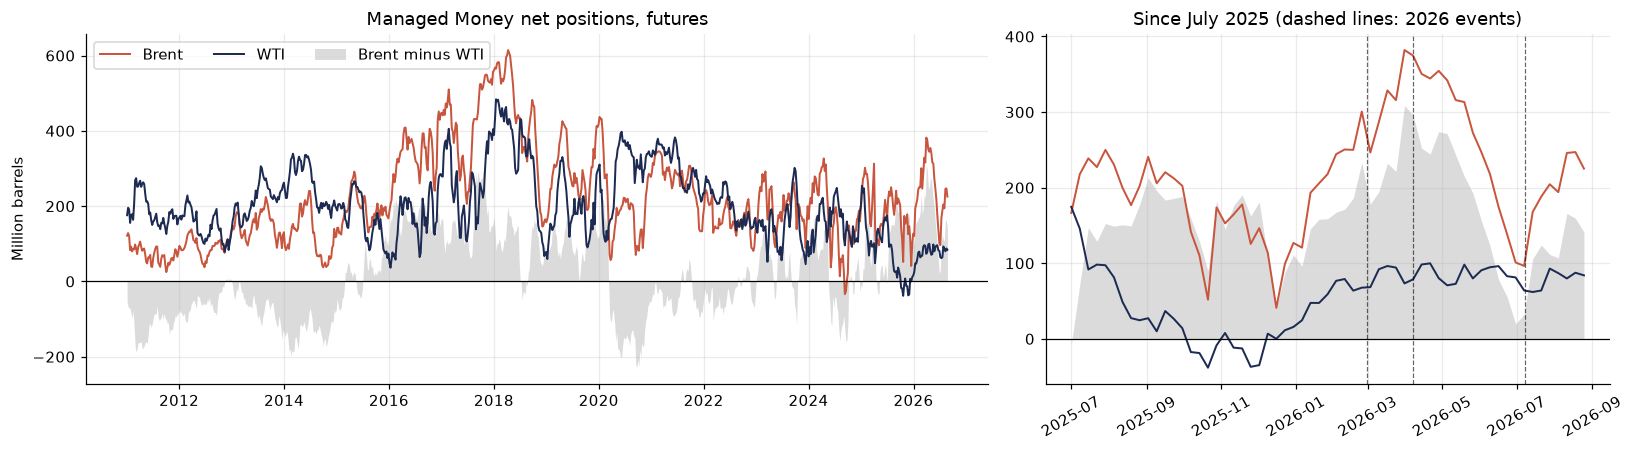

In [16]:
barrels = pos['net'][['BRENT', 'WTI']] / 1e3      # million barrels (1,000-barrel contracts)
gap = barrels['BRENT'] - barrels['WTI']
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={'width_ratios': [1.6, 1]})
for ax, span in [(ax1, (None, None)), (ax2, ('2025-07-01', None))]:
    ax.plot(barrels.loc[span[0]:].index, barrels.loc[span[0]:, 'BRENT'], color=COLORS['BRENT'], lw=1.3, label='Brent')
    ax.plot(barrels.loc[span[0]:].index, barrels.loc[span[0]:, 'WTI'], color=COLORS['WTI'], lw=1.3, label='WTI')
    ax.fill_between(gap.loc[span[0]:].index, 0, gap.loc[span[0]:], color='#9a9a9a', alpha=.35, lw=0, label='Brent minus WTI')
    ax.axhline(0, color='black', lw=.8)
    ax.grid(alpha=.25)
ax1.set(title='Managed Money net positions, futures', ylabel='Million barrels')
ax2.set(title='Since July 2025 (dashed lines: 2026 events)')
mark_events(ax2)
ax2.tick_params(axis='x', rotation=30)
ax1.legend(loc='upper left', ncol=3)
fig.tight_layout()
fig.savefig(OUTPUT / 'brent_wti_net.png', dpi=160)
print(f"Brent minus WTI: {gap.loc[:'2025'].mean():+.0f} mb on average 2011–2025, "
      f"{gap.loc['2026-02-24']:+.0f} mb on 24 Feb 2026, {gap.loc['2026'].max():+.0f} mb at its 2026 peak "
      f"({gap.loc['2026'].idxmax():%d %b}), {gap.iloc[-1]:+.0f} mb on {gap.index[-1]:%d %b %Y}")

,,Longs,Shorts,Net
market,phase (k contracts),,,
Brent,War to ceasefire,18.0,-56.0,74.0
WTI,War to ceasefire,-7.0,-18.0,11.0
Brent,Ceasefire,-160.0,119.0,-278.0
WTI,Ceasefire,6.0,21.0,-15.0
Brent,After collapse,79.0,-49.0,129.0
WTI,After collapse,4.0,-16.0,20.0


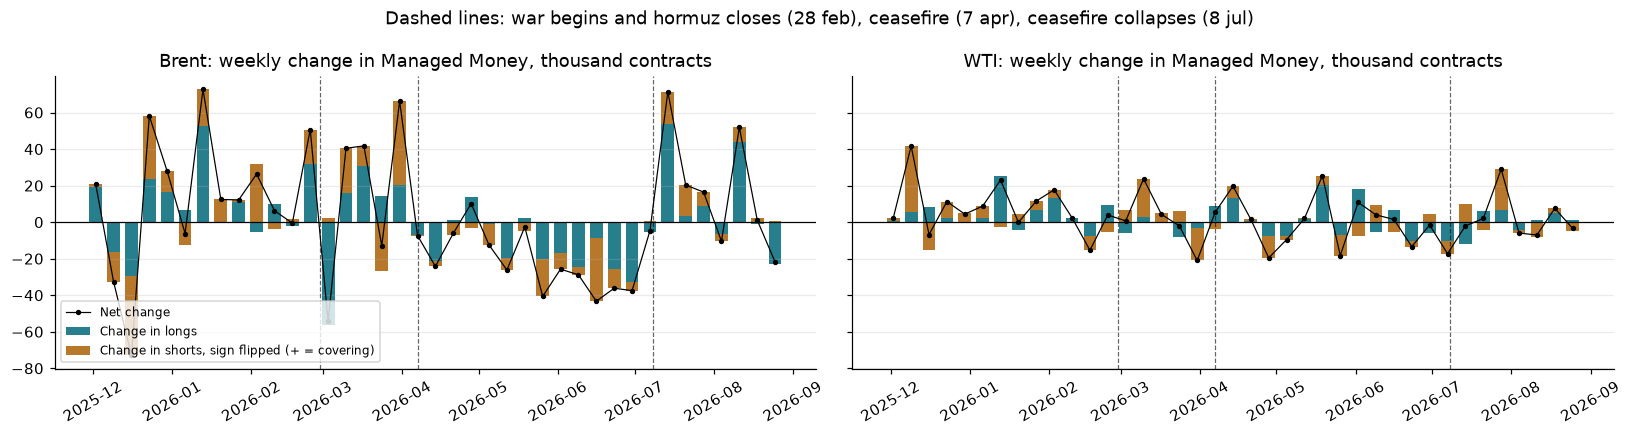

In [17]:
flows = pd.concat({'New longs': pos['long'].diff(), 'Short covering': -pos['short'].diff()}, axis=1).loc['2025-12-01':]
fig, axes = plt.subplots(1, 2, figsize=(15, 4), sharey=True)
for ax, m in zip(axes, ['BRENT', 'WTI']):
    longs, covers = flows[('New longs', m)] / 1e3, flows[('Short covering', m)] / 1e3
    ax.bar(longs.index, longs, width=5, color=COLORS['GASOIL'], label='Change in longs')
    ax.bar(covers.index, covers, width=5, bottom=np.where((longs > 0) == (covers > 0), longs, 0), color=COLORS['RBOB'],
           label='Change in shorts, sign flipped (+ = covering)')
    ax.plot(longs.index, longs + covers, color='black', marker='o', ms=2.5, lw=.8, label='Net change')
    ax.axhline(0, color='black', lw=.8)
    mark_events(ax)
    ax.set_title(f'{P.LABELS[m]}: weekly change in Managed Money, thousand contracts')
    ax.tick_params(axis='x', rotation=30)
    ax.grid(axis='y', alpha=.25)
axes[0].legend(fontsize=8, loc='lower left')
fig.suptitle(EVENT_NOTE.capitalize())
fig.tight_layout()
fig.savefig(OUTPUT / 'brent_wti_longs_shorts.png', dpi=160)
by_phase = {}
for name, (s, e) in list(phases.items())[1:]:
    for m in ['BRENT', 'WTI']:
        # From the last report before the phase to its last report
        by_phase[(P.LABELS[m], name)] = {side.capitalize() + 's': pos[side][m].loc[:e].iloc[-1] - pos[side][m].loc[:s].iloc[-2]
                                         for side in ('long', 'short')}
table = pd.DataFrame(by_phase).T.div(1e3)
table['Net'] = table['Longs'] - table['Shorts']
display(table.round(0).rename_axis(['market', 'phase (k contracts)']))

Brent–WTI weekly return correlation: 0.92 in 2011–2025, 0.97 in 2026; same-month spread 4.2 $/bbl on average 2016–2025, 4.0 Jul 2025 – Feb 2026, 7.0 since the war, peak 11.8 (05 May 2026)


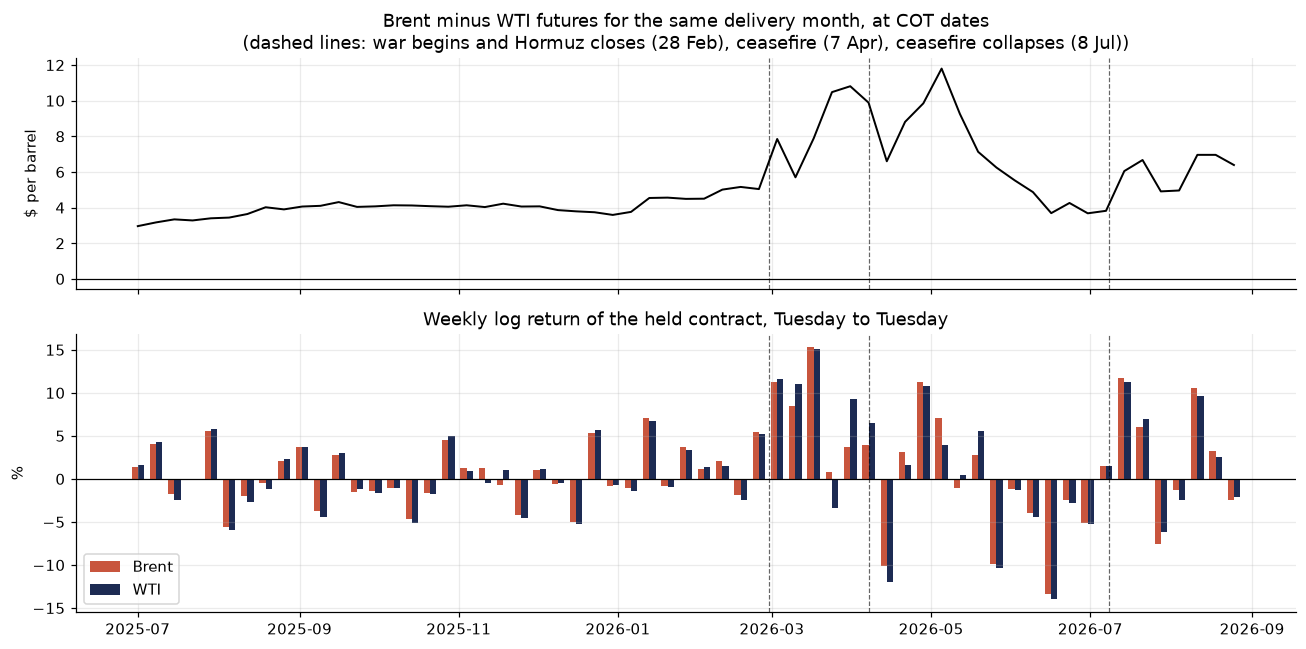

In [18]:
spread_all = P.matched_spread(prices, meta, pos['report_date'])
spread = spread_all.loc['2025-07-01':]
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw={'height_ratios': [1, 1.2]})
ax1.plot(spread.index, spread, color='black', lw=1.3)
ax1.set(title=f'Brent minus WTI futures for the same delivery month, at COT dates\n({EVENT_NOTE})', ylabel='$ per barrel')
r = returns.loc['2025-07-01':, ['BRENT', 'WTI']]
x = mdates.date2num(r.index)
ax2.bar(x - 1.2, r['BRENT'] * 100, width=2.4, color=COLORS['BRENT'], label='Brent')
ax2.bar(x + 1.2, r['WTI'] * 100, width=2.4, color=COLORS['WTI'], label='WTI')
ax2.set(title='Weekly log return of the held contract, Tuesday to Tuesday', ylabel='%')
ax2.legend(loc='lower left')
for ax in (ax1, ax2):
    mark_events(ax)
    ax.axhline(0, color='black', lw=.8)
    ax.grid(alpha=.25)
fig.tight_layout()
fig.savefig(OUTPUT / 'brent_wti_prices.png', dpi=160)
print(f"Brent–WTI weekly return correlation: {returns.loc[:'2025', 'BRENT'].corr(returns.loc[:'2025', 'WTI']):.2f} in 2011–2025, "
      f"{returns.loc['2026', 'BRENT'].corr(returns.loc['2026', 'WTI']):.2f} in 2026; "
      f"same-month spread {spread_all.loc['2016':'2025'].mean():.1f} $/bbl on average 2016–2025, "
      f"{spread.loc[:'2026-02-24'].mean():.1f} Jul 2025 – Feb 2026, {spread.loc['2026-03-03':].mean():.1f} since the war, "
      f"peak {spread.max():.1f} ({spread.idxmax():%d %b %Y})")

**Reading.** Funds' preference for Brent predates the war but peaked with it. Brent's net position exceeded WTI's by 12 million barrels on average in 2011–2025; by 24 February 2026 the gap was 233 million barrels, after WTI's net position had turned short for 8 weeks in October–December 2025, its only short weeks since 2011. The gap peaked at 309 million barrels on 31 March, the week Brent positions rose by 66k contracts while WTI's fell by 21k, then shrank to 20 million barrels by 30 June as funds sold Brent for ten weeks in a row (5 May – 7 July). Over the ceasefire, Brent longs fell by 160k contracts and shorts rose by 119k, while WTI's net position moved by 15k. After the ceasefire collapsed, funds bought Brent back (+129k, mostly new longs) and the gap was 141 million barrels on 25 August.

Prices do not explain the split on their own: Brent and WTI returns correlated 0.97 in 2026. The same-month Brent–WTI spread, near $4 before the war (2016–2025 average $4.2), widened to $10.8 at the end of March and $11.8 on 5 May, narrowed below $4 by mid-June, and widened again after the collapse. Brent length built as the spread first widened and was liquidated as it narrowed, consistent with positioning for a shock to seaborne crude, which is priced off Brent, rather than for oil in general.

## Interpretation

**Normal times.** Managed Money positions in the oil complex move together because trend followers react to prices that move together: most of the co-movement disappears in the discretionary part. Since 2020 that co-movement has weakened, with each market's positions following more of their own drivers.

**2026.** The war split the block. Prices stayed tied, and so did the trend signals they generate, but funds kept following those signals only in Brent; in WTI and the products they stopped, which is what broke the correlations. This matches the OIES comment on three points: once the first shock passed, positions tracked prices again in Brent but not in WTI, so trend following ran through Brent; WTI and the products were driven by discretionary positioning that moved together; and discretionary length rotated from Brent to the products (and WTI) from April. The comment's explanations for Brent's role are that it prices the seaborne crude exposed to the Strait, that Asian buyers switched the pricing of US crude from Dubai to Brent in late March, and that physical hedgers went short Brent to hedge replacement barrels and long WTI against the obligation to return Strategic Petroleum Reserve barrels. Producer and merchant positions are not in our data, so we cannot test that last link.

**Caveats.**
- 2026 has 34 weeks, and the phases between events 6 to 13 weeks: phase correlations are imprecise.
- Our discretionary part comes from the original six-market Insight 177 network, refitted weekly on two years. The comment uses a variant on 29 commodities with a one-year window, which may explain the differences (Brent's early-war price link, Gasoil in July).
- Futures only: the comment notes that funds moved to options during the crisis, which these positions miss.
- Event dates differ by a day across sources, and COT weeks end on Tuesday, so each event falls inside a reporting week.

**Next steps.** Disaggregated COT data (producers and merchants, swap dealers) to test the hedging explanation; futures-plus-options positions; the rest of 2026 when it is available; and a market-specific, time-varying trend loading for the Insight 177 nowcast, whose shared momentum layer kept implying trend-following flows in WTI and the products in 2026 that did not happen.

## Save results

In [19]:
pd.concat(full, axis=0).to_csv(OUTPUT / 'full_sample_matrices.csv')
pd.concat(roll, axis=1).to_csv(OUTPUT / 'rolling_correlations_26w.csv')
pd.concat(short, axis=1).to_csv(OUTPUT / 'rolling_correlations_13w.csv')
pd.DataFrame({'regime': regimes}).to_csv(OUTPUT / 'regimes.csv')
own.to_csv(OUTPUT / 'own_return_correlation_by_phase.csv')
pd.concat([split, slopes], axis=1).to_csv(OUTPUT / 'correlation_split_26w.csv')
episodes.to_csv(OUTPUT / 'low_correlation_episodes.csv')

## References

- Sun, W.-Y., Bouchouev, I. and Fattouh, B. (2026), *Shifting Oil Market Positioning During the Strait of Hormuz Crisis*, OIES Energy Comment, October (`Papers/Comment-Shifting-Oil-Market-Positioning.pdf`).
- Sun, W.-Y., Bouchouev, I. and Fattouh, B. (2026), *Momentum Trading and Managed Money Positioning in Energy: Relationships and Practical Applications*, OIES Energy Insight 177, March (`Papers/Insight-177-Money-Positioning-in-Energy.pdf`), replicated in `paper_replication/`.
- Event dates: [2026 Iran war](https://en.wikipedia.org/wiki/2026_Iran_war) and [2026 Strait of Hormuz crisis](https://en.wikipedia.org/wiki/2026_Strait_of_Hormuz_crisis) (Wikipedia), [hormuz.now timeline](https://hormuz.now/timeline), [CRS R45281](https://www.congress.gov/crs-product/R45281).